📊 Dimensões do dataset: 8640 janelas x 20 colunas
🔍 Total de valores nulos: 0
🔁 Janelas duplicadas: 0

📋 Distribuição dos Comportamentos (Vaca T01):
          Janelas (10s)  Tempo Total (min)  Proporção (%)
behavior                                                 
7                  4468              744.7          51.71
2                  1521              253.5          17.60
0                  1503              250.5          17.40
4                   631              105.2           7.30
3                   315               52.5           3.65
1                   105               17.5           1.22
6                    97               16.2           1.12


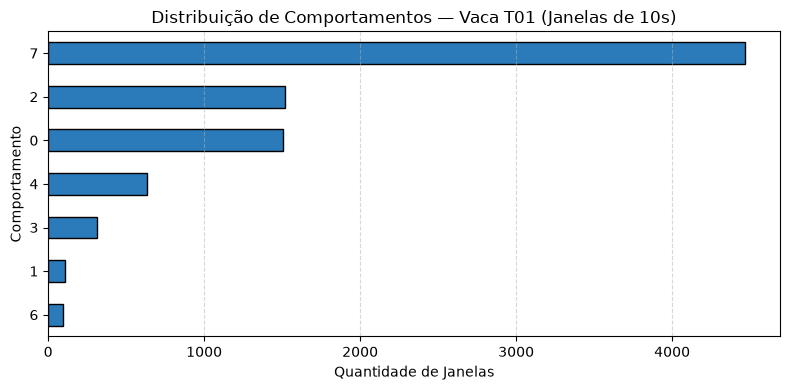

In [2]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Carregar o arquivo limpo da vaca T01
caminho_t01 = os.path.join("./dados/clean", "T01.csv")
df_t01 = pd.read_csv(caminho_t01)

# 2. Auditoria de sanidade (formato, nulos e duplicatas)
print(f"📊 Dimensões do dataset: {df_t01.shape[0]} janelas x {df_t01.shape[1]} colunas")
print(f"🔍 Total de valores nulos: {df_t01.isnull().sum().sum()}")
print(f"🔁 Janelas duplicadas: {df_t01['janela'].duplicated().sum()}")

# 3. Tabela com contagem absoluta e percentual de cada comportamento
contagem = df_t01["behavior"].value_counts()
percentual = (df_t01["behavior"].value_counts(normalize=True) * 100).round(2)

resumo_classes = pd.DataFrame(
    {
        "Janelas (10s)": contagem,
        "Tempo Total (min)": (contagem * 10 / 60).round(1),
        "Proporção (%)": percentual,
    }
)
print("\n📋 Distribuição dos Comportamentos (Vaca T01):")
print(resumo_classes)

# 4. Gráfico de barras horizontal para visualização rápida
plt.figure(figsize=(8, 4))
contagem.sort_values().plot(kind="barh", color="#2b7bba", edgecolor="black")
plt.title("Distribuição de Comportamentos — Vaca T01 (Janelas de 10s)")
plt.xlabel("Quantidade de Janelas")
plt.ylabel("Comportamento")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()